# Características de dados de Série Temporal

1. Dados são imutáveis e apenas adicionados
2. Dados chegam em ordem temporal
3. Tempo é um eixo primário.
4. Intervalos de tempo podem ser regulares (métricas) ou irregulares (eventos)

## Análise de Séries Temporais

- Visualização
- Decomposição (com o Prophet)
- Autocorrelação

# Objetivos de uma Análise de Série Temporal

- (Descrição) Avaliar o impacto de um evento único
- (Explicação) Estudo de padrões causais, ou seja, efeitos de variáveis em vez de eventos
- (Predição) Predizer valores futuros da série usando valores anteriores dela.

In [1]:
# No Google Colab o Prophet já vem instalado. Em outro ambiente, descomente a linha abaixo:
# !pip install prophet

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from prophet import Prophet
import logging
logging.getLogger('cmdstanpy').setLevel(logging.WARNING)  # reduz mensagens de log

# https://www.kaggle.com/datasets/rakannimer/air-passengers

df=pd.read_csv("https://raw.githubusercontent.com/celsocrivelaro/simple-datasets/main/AirPassengers.csv")

df.head()

Importing plotly failed. Interactive plots will not work.


,Month,#Passengers
0,1949-01,112
1,1949-02,118
2,1949-03,132
3,1949-04,129
4,1949-05,121


<Axes: xlabel='Month'>

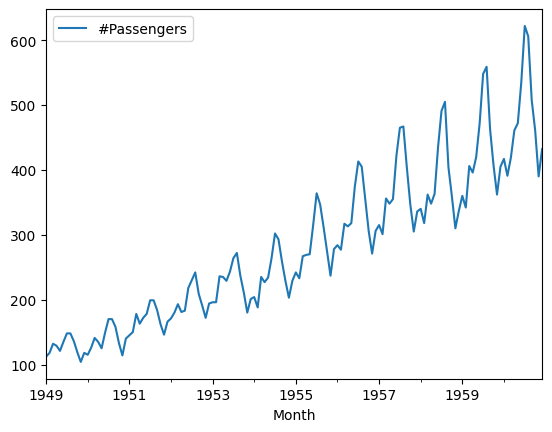

In [2]:
df.set_index('Month',inplace=True)
df.index=pd.to_datetime(df.index)
#drop null values
df.dropna(inplace=True)
df.plot()

# O Prophet

O [Prophet](https://facebook.github.io/prophet/) é uma biblioteca de séries temporais criada pela Meta (Facebook). Ele trata a série como um problema de **ajuste de curvas**, decompondo-a em componentes interpretáveis. Neste notebook vamos usá-lo para **decompor** a série:

$$
y(t) = g(t) + s(t) + h(t) + \varepsilon_t
$$

- $g(t)$: **tendência** — linear (ou logística) *por partes*, com **pontos de mudança** (*changepoints*) detectados automaticamente;
- $s(t)$: **sazonalidade** — modelada com séries de Fourier (anual, semanal, diária ou personalizada);
- $h(t)$: efeito de **feriados e eventos** (opcional);
- $\varepsilon_t$: erro.

No modo **multiplicativo**, a sazonalidade é proporcional à tendência: $y(t) = g(t)\,\big(1 + s(t) + h(t)\big) + \varepsilon_t$.

**Vantagens**: fácil de usar, componentes interpretáveis, lida bem com dados faltantes e mudanças de tendência, e gera intervalos de incerteza.
**Limitações**: não modela explicitamente a autocorrelação dos erros (como o ARIMA faz) e tende a funcionar melhor com séries longas e com sazonalidade forte.

### Formato dos dados

O Prophet exige um DataFrame com exatamente duas colunas:
- `ds`: data (datetime);
- `y`: valor numérico da série.

In [3]:
df_prophet = df.reset_index().rename(columns={'Month': 'ds', '#Passengers': 'y'})
df_prophet.head()

,ds,y
0,1949-01-01,112
1,1949-02-01,118
2,1949-03-01,132
3,1949-04-01,129
4,1949-05-01,121


## Decomposição

Aditiva: trend + cyclic + seasonality + noise

Multiplicativa: trend * cyclic * seasonality * noise

Qual escolher? Modelo aditivo é útil quando a variação de sazonalidade é constante ao longo do tempo, já o modelo multiplicativo é útil quando a variação de sazonalidade aumenta ao longo do tempo.

No Prophet, a escolha é feita pelo parâmetro `seasonality_mode`. A componente cíclica não é separada: ela fica incorporada à tendência $g(t)$, que pode mudar de inclinação nos *changepoints*. Para **descrever** a série, ajustamos o modelo com **todos** os dados e olhamos seus componentes com `plot_components`.

Como os dados são mensais, desligamos as sazonalidades semanal e diária, que não fazem sentido aqui.

/usr/local/lib/python3.12/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
01:45:19 - cmdstanpy - INFO - Chain [1] start processing


01:45:19 - cmdstanpy - INFO - Chain [1] done processing


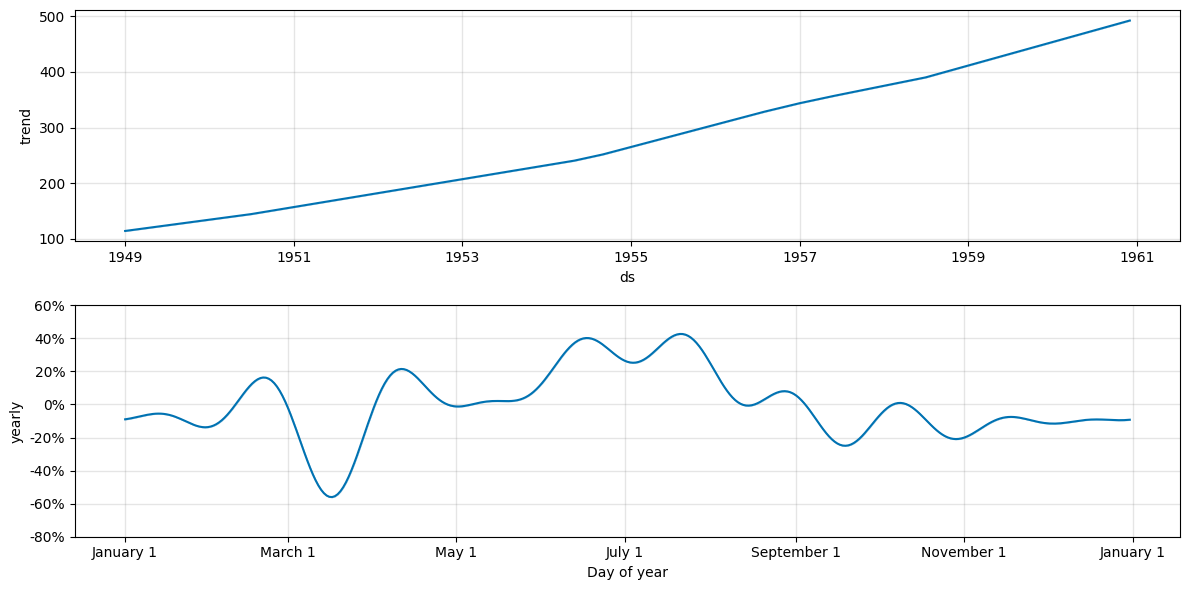

In [4]:
decomp_mult = Prophet(seasonality_mode='multiplicative', yearly_seasonality=True,
                      weekly_seasonality=False, daily_seasonality=False)
decomp_mult.fit(df_prophet)
ajuste_mult = decomp_mult.predict(df_prophet[['ds']])

fig = decomp_mult.plot_components(ajuste_mult, figsize=(12, 6))
plt.show()

01:45:19 - cmdstanpy - INFO - Chain [1] start processing


01:45:19 - cmdstanpy - INFO - Chain [1] done processing


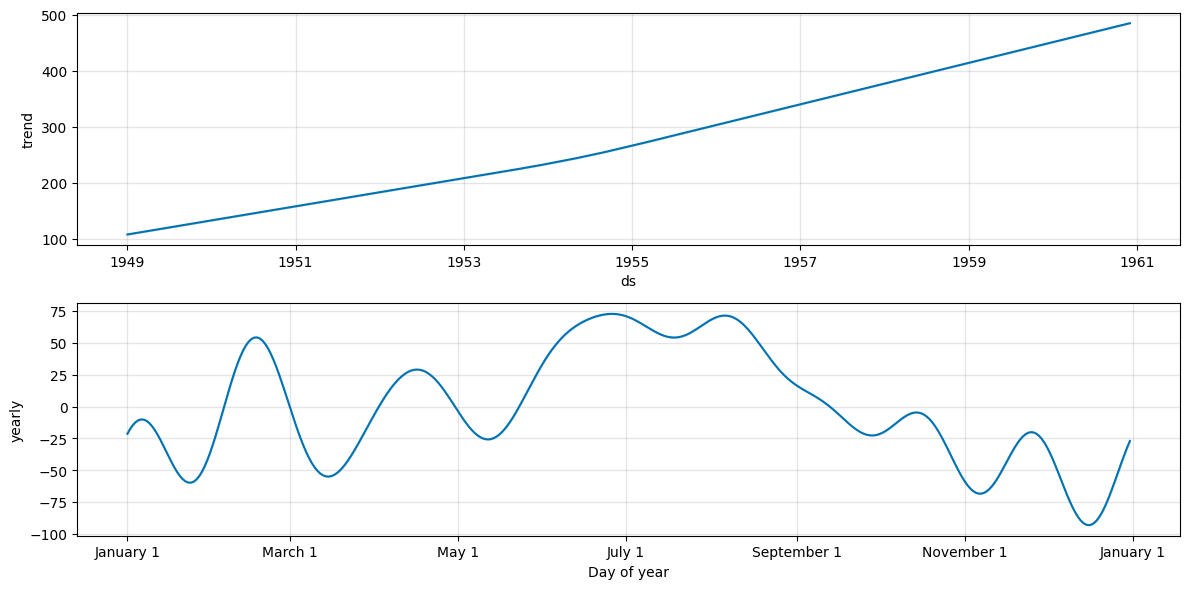

In [5]:
decomp_adit = Prophet(seasonality_mode='additive', yearly_seasonality=True,
                      weekly_seasonality=False, daily_seasonality=False)
decomp_adit.fit(df_prophet)
ajuste_adit = decomp_adit.predict(df_prophet[['ds']])

fig = decomp_adit.plot_components(ajuste_adit, figsize=(12, 6))
plt.show()

Repare na unidade do componente **yearly** em cada caso:

- **Multiplicativo**: o eixo está em **percentual** da tendência (ex.: +24% em julho). O efeito sazonal em número de passageiros cresce junto com a série.
- **Aditivo**: o eixo está em **número de passageiros** e a amplitude é a mesma em 1949 e em 1960.

Para decidir, comparamos o ajuste de cada modo com os dados reais.

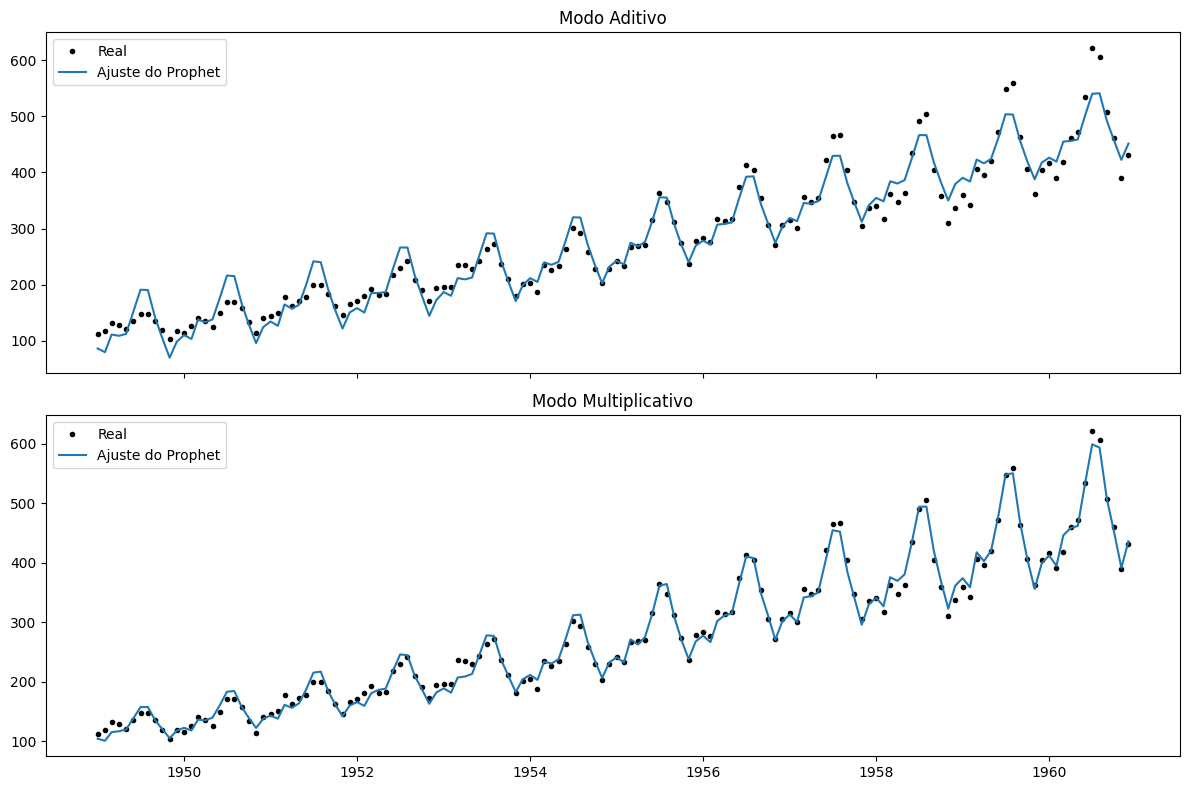

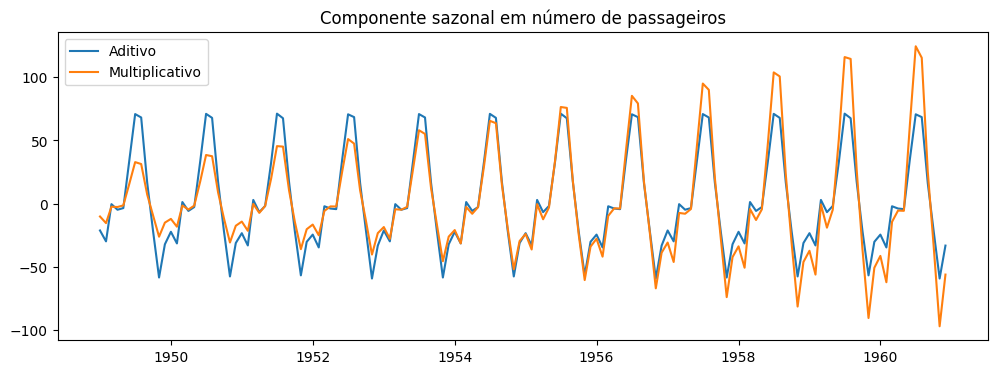

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
for ax, ajuste, titulo in [(axes[0], ajuste_adit, 'Aditivo'), (axes[1], ajuste_mult, 'Multiplicativo')]:
    ax.plot(df_prophet.ds, df_prophet.y, 'k.', label='Real')
    ax.plot(ajuste.ds, ajuste.yhat, label='Ajuste do Prophet')
    ax.set_title(f'Modo {titulo}')
    ax.legend()
plt.tight_layout()
plt.show()

# Efeito sazonal em número de passageiros (sazonalidade sobre a tendência)
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(ajuste_adit.ds, ajuste_adit.yearly, label='Aditivo')
ax.plot(ajuste_mult.ds, ajuste_mult.yearly * ajuste_mult.trend, label='Multiplicativo')
ax.set_title('Componente sazonal em número de passageiros')
ax.legend()
plt.show()

### Interpretação

- No modo **aditivo**, a sazonalidade tem amplitude fixa: o modelo **exagera** as oscilações nos primeiros anos e as **subestima** nos últimos.
- No modo **multiplicativo**, a amplitude cresce junto com a tendência e o ajuste acompanha os picos e vales em todo o período.
- Conclusão: para esta série, a decomposição **multiplicativa** é a mais adequada.

## Autocorrelação

### O que é

A **autocorrelação** mede o quanto uma série temporal se parece com **uma cópia dela mesma deslocada no tempo**. Em vez de correlacionar duas variáveis diferentes (como na correlação de Pearson), correlacionamos a série $y_t$ com seus próprios valores passados $y_{t-k}$.

O deslocamento $k$ é chamado de **lag** (defasagem). Com dados mensais:

- lag 1 → compara cada mês com o mês anterior;
- lag 12 → compara cada mês com o mesmo mês do ano anterior.

A autocorrelação no lag $k$ é estimada por:

$$
r_k = \frac{\sum_{t=k+1}^{T} (y_t - \bar{y})(y_{t-k} - \bar{y})}{\sum_{t=1}^{T} (y_t - \bar{y})^2}
$$

Assim como uma correlação comum, $r_k$ varia entre $-1$ e $+1$:

- $r_k$ próximo de **+1**: valores altos tendem a ser seguidos, $k$ períodos depois, por valores altos;
- $r_k$ próximo de **−1**: valores altos tendem a ser seguidos por valores baixos;
- $r_k$ próximo de **0**: o valor de $k$ períodos atrás não ajuda a prever o valor atual (de forma linear).

### Por que isso importa

Muitos métodos estatísticos supõem que as observações são **independentes**. Em séries temporais isso quase nunca acontece: o valor de hoje depende do de ontem. A autocorrelação serve para:

1. **Diagnosticar a estrutura da série** — tendência e sazonalidade deixam “assinaturas” características no gráfico;
2. **Verificar estacionariedade** — séries com tendência têm autocorrelação que decai muito lentamente;
3. **Escolher modelos** — em modelos ARIMA, a ACF e a PACF ajudam a definir as ordens dos termos;
4. **Avaliar um modelo já ajustado** — se o modelo capturou toda a estrutura, os **resíduos** devem ter autocorrelação próxima de zero (ruído branco). Faremos isso com o Prophet mais adiante.

### Como ler o correlograma (gráfico da ACF)

- **Eixo x**: os lags $k = 0, 1, 2, \dots$
- **Eixo y**: o valor de $r_k$.
- **Lag 0** sempre vale 1 (a série é perfeitamente correlacionada consigo mesma) e pode ser ignorado.
- **Área azul**: intervalo de confiança de 95% sob a hipótese de que **não há** autocorrelação naquele lag. Barras **fora** da área azul indicam autocorrelação estatisticamente significativa; barras **dentro** são compatíveis com zero.
  - A área se alarga conforme o lag aumenta (fórmula de Bartlett), porque a incerteza acumula.
  - Com 95% de confiança, espera-se que cerca de 1 em cada 20 barras saia da área **por acaso**. Uma barra isolada, num lag sem significado prático, não deve ser superinterpretada.

### Padrões típicos

| O que vemos na ACF | O que costuma indicar |
|---|---|
| Valores altos que **decaem lentamente** | **Tendência** / série não estacionária |
| **Picos** em lags múltiplos de $s$ (ex.: 12, 24, 36) | **Sazonalidade** de período $s$ |
| Queda **rápida** para dentro da área azul | Série estacionária, memória curta |
| Sinais que **alternam** (+, −, +, −) | Comportamento oscilatório |
| Praticamente tudo **dentro** da área azul | **Ruído branco** — não há estrutura linear a explorar |

### Calculando a ACF e a PACF

Como estamos usando apenas o Prophet (que não tem funções de autocorrelação), implementamos o cálculo diretamente com NumPy, seguindo a fórmula acima. Isso também ajuda a entender o que o gráfico mostra.

- **Intervalo de confiança da ACF** (fórmula de Bartlett): $\pm 1{,}96\,\sqrt{\dfrac{1 + 2\sum_{j=1}^{k-1} r_j^2}{T}}$
- **PACF**: calculada a partir da ACF pelo algoritmo de Durbin–Levinson, com intervalo $\pm 1{,}96/\sqrt{T}$.

In [7]:
def acf(x, nlags):
    """Autocorrelação r_k para k = 0..nlags."""
    x = np.asarray(x, dtype=float)
    x = x - x.mean()
    denominador = np.sum(x ** 2)
    return np.array([np.sum(x[k:] * x[:len(x) - k]) / denominador for k in range(nlags + 1)])


def pacf(x, nlags):
    """Autocorrelação parcial pelo algoritmo de Durbin-Levinson."""
    r = acf(x, nlags)
    phi = np.zeros((nlags + 1, nlags + 1))
    resultado = [1.0, r[1]]
    phi[1, 1] = r[1]
    for k in range(2, nlags + 1):
        num = r[k] - np.sum(phi[k - 1, 1:k] * r[k - 1:0:-1])
        den = 1 - np.sum(phi[k - 1, 1:k] * r[1:k])
        phi[k, k] = num / den
        for j in range(1, k):
            phi[k, j] = phi[k - 1, j] - phi[k, k] * phi[k - 1, k - j]
        resultado.append(phi[k, k])
    return np.array(resultado)


def plot_acf(x, lags, ax, parcial=False, titulo=None):
    """Correlograma com intervalo de confiança de 95% (área azul)."""
    n = len(x)
    valores = pacf(x, lags) if parcial else acf(x, lags)
    k = np.arange(lags + 1)
    if parcial:
        limite = np.full(lags + 1, 1.96 / np.sqrt(n))
    else:
        limite = 1.96 * np.sqrt((1 + 2 * np.concatenate([[0, 0], np.cumsum(valores[1:-1] ** 2)])) / n)
    limite[0] = np.nan
    ax.fill_between(k, -limite, limite, alpha=0.25, label='IC 95%')
    ax.vlines(k, 0, valores)
    ax.plot(k, valores, 'o', markersize=4)
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_ylim(-1.1, 1.1)
    ax.set_xlabel('Lag (meses)')
    ax.set_title(titulo or ('PACF' if parcial else 'ACF'))
    return valores

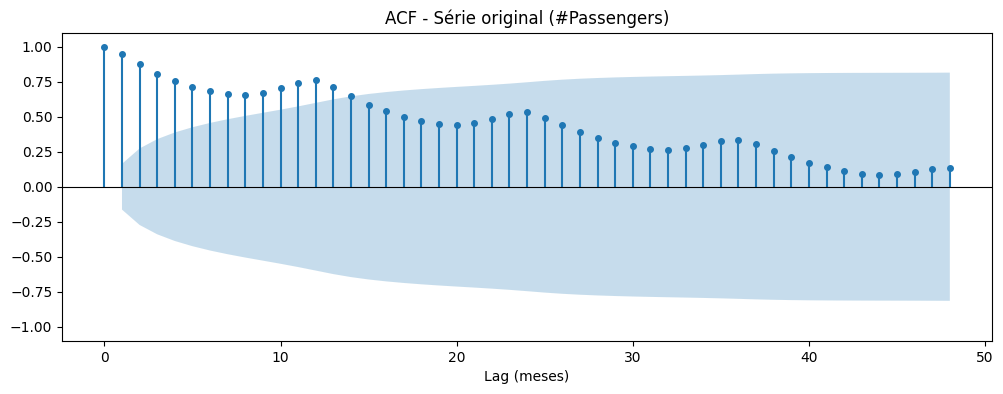

lag  1: r = 0.95
lag  6: r = 0.68
lag 12: r = 0.76
lag 18: r = 0.47
lag 24: r = 0.53


In [8]:
# ACF da série original (até 48 lags = 4 anos)
fig, ax = plt.subplots(figsize=(12, 4))
plot_acf(df['#Passengers'], lags=48, ax=ax, titulo='ACF - Série original (#Passengers)')
plt.show()

valores_acf = acf(df['#Passengers'], nlags=24)
for lag in [1, 6, 12, 18, 24]:
    print(f'lag {lag:2d}: r = {valores_acf[lag]:.2f}')

### Interpretação — série original

1. **Autocorrelação muito alta e com decaimento lento**: no lag 1, $r \approx 0{,}95$, e mesmo depois de 2 anos (lag 24) ainda está em torno de $0{,}5$. Isso é a assinatura de uma **tendência**: como o número de passageiros cresce ano após ano, qualquer mês é “parecido” com os meses próximos simplesmente porque estão no mesmo patamar. A série **não é estacionária**.
2. **“Ondulação” com picos nos lags 12, 24, 36…**: a curva cai até os lags 6–8, volta a subir no lag 12, cai de novo por volta do lag 18 e sobe no 24. Esse é o sinal da **sazonalidade anual** que já vimos na decomposição: julho se parece com o julho anterior; o lag 6 compara meses “opostos” do ciclo (por exemplo, julho com janeiro), por isso é mais baixo.

**Problema**: a tendência domina o gráfico e “esconde” os outros padrões. Para enxergar melhor a dependência entre os meses, removemos a tendência.

### Removendo a tendência

Duas transformações clássicas:

- **Logaritmo**: estabiliza a variância. Como a sazonalidade aqui é *multiplicativa* (as oscilações crescem com o nível), o log a transforma em aditiva.
- **Diferenciação** ($y_t - y_{t-1}$): remove a tendência, pois passamos a olhar para a **variação** mês a mês, e não para o nível.

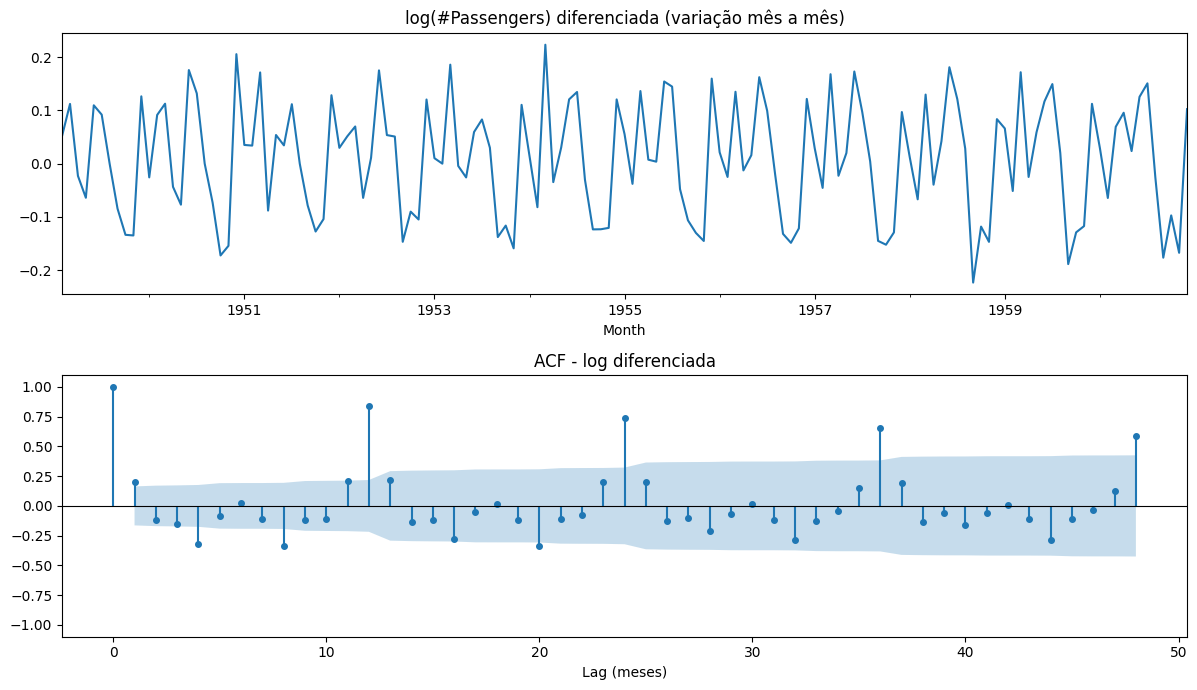

lag  1: r = 0.20
lag  4: r = -0.32
lag  8: r = -0.34
lag 12: r = 0.84
lag 24: r = 0.74


In [9]:
serie_log_diff = np.log(df['#Passengers']).diff().dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 7))
serie_log_diff.plot(ax=axes[0], title='log(#Passengers) diferenciada (variação mês a mês)')
plot_acf(serie_log_diff, lags=48, ax=axes[1], titulo='ACF - log diferenciada')
plt.tight_layout()
plt.show()

valores_acf = acf(serie_log_diff, nlags=24)
for lag in [1, 4, 8, 12, 24]:
    print(f'lag {lag:2d}: r = {valores_acf[lag]:.2f}')

### Interpretação — série diferenciada

- O decaimento lento **desapareceu**: a maior parte dos lags agora fica perto de zero. A tendência foi removida.
- Os **picos nos lags 12 e 24** (cerca de $0{,}84$ e $0{,}74$) agora saltam aos olhos: a variação de um mês é muito parecida com a variação do mesmo mês no ano anterior. É a **sazonalidade anual** aparecendo de forma limpa.
- Lags como 4 e 8 negativos refletem a forma do ciclo dentro do ano (meses de alta seguidos de meses de queda).

Para remover também a sazonalidade, aplicamos uma **diferença sazonal** ($y_t - y_{t-12}$).

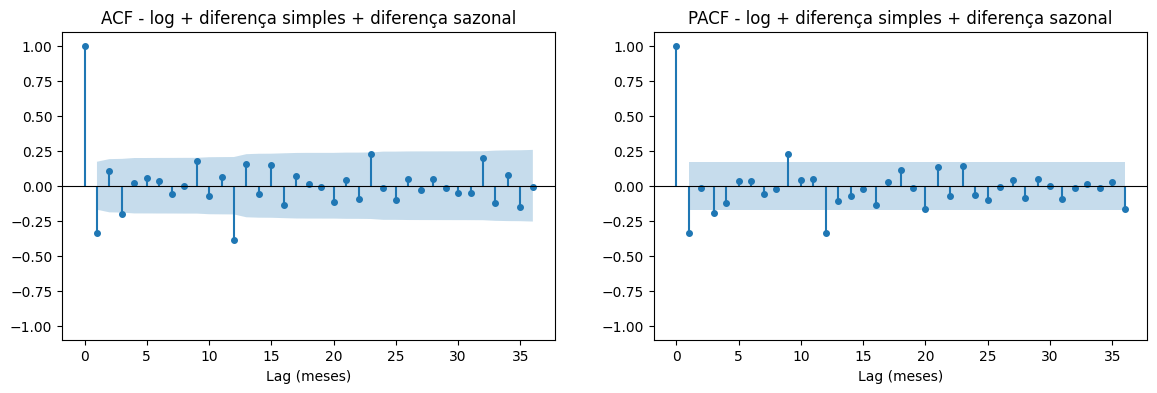

In [10]:
serie_estacionaria = np.log(df['#Passengers']).diff().diff(12).dropna()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(serie_estacionaria, lags=36, ax=axes[0], titulo='ACF - log + diferença simples + diferença sazonal')
plot_acf(serie_estacionaria, lags=36, ax=axes[1], parcial=True, titulo='PACF - log + diferença simples + diferença sazonal')
plt.show()

### Interpretação — após diferença simples e sazonal

- Quase todas as barras estão **dentro** do intervalo de confiança: a série resultante é aproximadamente **estacionária**.
- Restam poucos lags significativos, principalmente o **lag 1** e o **lag 12**, ambos negativos (cerca de $-0{,}34$ e $-0{,}39$). Esse padrão (“cortes” isolados em 1 e 12) é o clássico do chamado *airline model*, um SARIMA$(0,1,1)(0,1,1)_{12}$ — justamente o modelo que Box e Jenkins propuseram para esta série.

**ACF × PACF**: a **PACF** (autocorrelação *parcial*) mede a correlação entre $y_t$ e $y_{t-k}$ **descontando o efeito dos lags intermediários**. Exemplo: se $y_t$ depende de $y_{t-1}$, que depende de $y_{t-2}$, a ACF no lag 2 será alta “por tabela”, mas a PACF no lag 2 será próxima de zero. Na modelagem ARIMA, a PACF ajuda a escolher a ordem dos termos autorregressivos (AR) e a ACF, a dos termos de média móvel (MA).

### Resumo do que a autocorrelação nos disse

| Etapa | ACF | Conclusão |
|---|---|---|
| Série original | Alta, decaimento lento, ondulação de período 12 | Tendência + sazonalidade anual |
| Após log + diferença | Picos fortes em 12, 24 | Tendência removida, sazonalidade clara |
| Após diferença sazonal | Quase tudo no intervalo | Série ~estacionária; estrutura residual nos lags 1 e 12 |

## Autocorrelação dos resíduos da decomposição

A autocorrelação também serve para avaliar a **decomposição**. O resíduo é o que sobra depois de retirar a tendência e a sazonalidade:

$$\text{resíduo}_t = y_t - \hat{y}_t$$

Se a decomposição capturou toda a estrutura da série, o resíduo deveria ser **ruído branco**, com a ACF praticamente toda dentro do intervalo de confiança. Se ainda houver autocorrelação significativa, existe algum padrão que a decomposição **não explicou**.

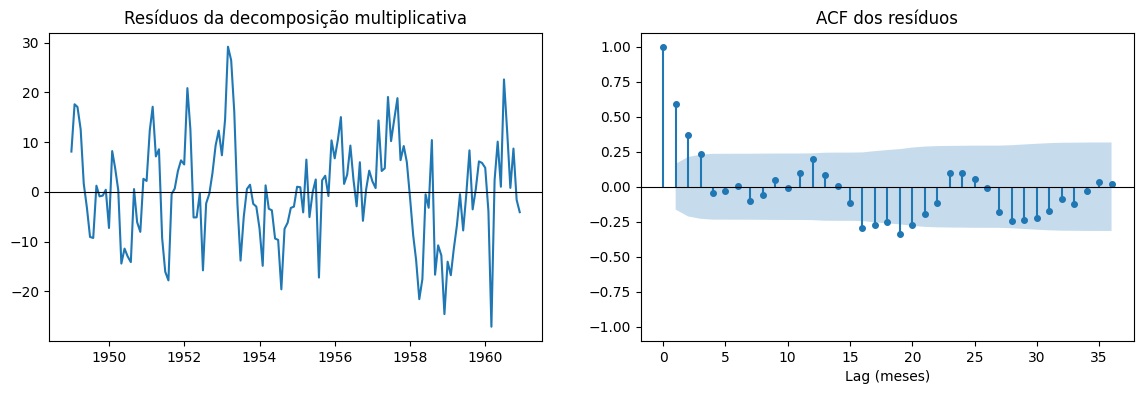

lag  1: r = 0.59
lag  2: r = 0.37
lag  3: r = 0.23
lag 12: r = 0.20


In [11]:
residuos = df_prophet.y.values - ajuste_mult.yhat.values

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(df_prophet.ds, residuos)
axes[0].axhline(0, color='black', linewidth=0.8)
axes[0].set_title('Resíduos da decomposição multiplicativa')
plot_acf(residuos, lags=36, ax=axes[1], titulo='ACF dos resíduos')
plt.show()

valores_acf = acf(residuos, nlags=12)
for lag in [1, 2, 3, 12]:
    print(f'lag {lag:2d}: r = {valores_acf[lag]:.2f}')

### Interpretação dos resíduos

- Comparando com a ACF da série original, quase toda a estrutura foi removida: não há mais o decaimento lento (tendência), e o lag 12 ($r \approx 0{,}20$) ficou dentro do intervalo — a sazonalidade foi bem capturada.
- Porém, os **primeiros lags ainda têm autocorrelação positiva significativa**: quando a série fica acima do esperado em um mês, tende a ficar acima no mês seguinte também. Os lags 1 e 2 ($r \approx 0{,}59$ e $0{,}37$) estão claramente fora do intervalo: são desvios de curto prazo que duram alguns meses.
- Esses desvios persistem porque o Prophet descreve a série como uma **função do tempo** (tendência + sazonalidade) e não usa o valor do mês anterior para explicar o mês atual.
- Alguns lags negativos entre 16 e 19 encostam no limite do intervalo. Isso reflete as ondulações lentas visíveis no gráfico dos resíduos, mas, como são poucos e marginais, lembre-se da regra de que cerca de 1 em cada 20 barras sai do intervalo por acaso.

## Para discutir

1. Faça a decomposição com `changepoint_prior_scale` igual a 0.01 e 0.5. O que acontece com a tendência e com a ACF dos resíduos?
2. Faça a decomposição de `np.log(y)` no modo aditivo e compare com o modo multiplicativo. Por que os resultados são parecidos?
3. Como ficaria a ACF dos resíduos de uma decomposição que **ignora** a sazonalidade (`yearly_seasonality=False`)? O que esperamos ver no lag 12?